c:\Users\raoaf\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6031 - loss: 1.3033
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7694 - loss: 0.8330
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8044 - loss: 0.5092
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8275 - loss: 0.4472
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8306 - loss: 0.4202
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8562 - loss: 0.3938
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8731 - loss: 0.3522
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8825 - loss: 0.3297
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8913 - loss: 0.3127
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8963 - loss: 0.2872
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9137 - loss: 0.2585
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accura

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153,530 (599.73 KB)

 Trainable params: 51,176 (199.91 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 102,354 (399.82 KB)

None
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9550 - loss: 0.1507  
Loss:  0.15074756741523743
Accuracy:  0.9549999833106995


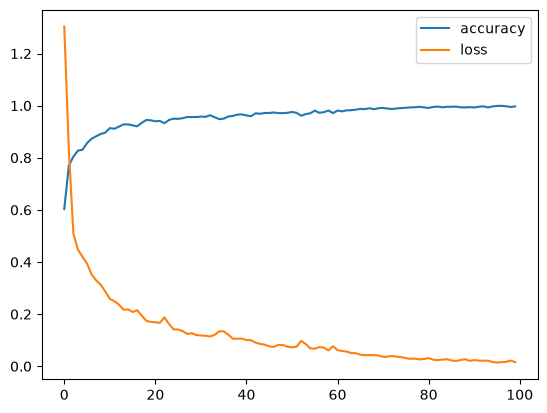

In [4]:
import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, AveragePooling2D, Flatten, Conv2D
from keras.utils import to_categorical


csv_path = r'C:\My Files\ANN & ML Projects\ANNDL_Fall_2026\Project_ANNDL_Fall_2026\data\processed\Images32.csv'
data = pd.read_csv(csv_path, header=None)

Y = data.iloc[:, 0].values
X = data.iloc[:, 1:].values
X = X.reshape(-1, 32, 32, 1)
X = X.astype('float32') / 255.0

Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=42)

num_classes = 4
Ytrain = to_categorical(Ytrain, num_classes)
Ytest = to_categorical(Ytest, num_classes)

cnn = Sequential()
cnn.add(Conv2D(filters=6, kernel_size=(5, 5), activation='relu', input_shape=(32, 32, 1)))
cnn.add(AveragePooling2D(pool_size=(2, 2), strides=(2, 2)))
cnn.add(Conv2D(filters=16, kernel_size=(5, 5), activation='relu', padding='valid', strides=(1, 1)))
cnn.add(AveragePooling2D((2, 2), strides=(2, 2)))
cnn.add(Conv2D(filters=120, kernel_size=(5, 5), activation='relu', padding='valid', strides=(1, 1)))
cnn.add(Flatten())
cnn.add(Dense(4, activation='softmax'))

cnn.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

result = cnn.fit(Xtrain, Ytrain, epochs=100, batch_size=128, verbose=1)
print(cnn.summary())
loss,acc = cnn.evaluate(Xtest,Ytest)
print("Loss: ", loss)
print("Accuracy: ",acc)
pd.DataFrame(result.history).plot()
plt.show()
cnn.save('C:\\My Files\\ANN & ML Projects\\ANNDL_Fall_2026\\Project_ANNDL_Fall_2026\\models\\images32_leet_model.keras')